# STEP10. 산업 재무특성과 금리베타 탐색 (H3)

## 분석 질문

- 산업별 금리베타는 부채비율·배당수익률의 산업 간 순위와 어떤 방향으로 정렬되는가?
- 관련 가설: H3(모형 E) — 재무특성이 산업별 금리민감도 차이와 연관되는가?

## 입력

- 입력 파일: `data/raw/firm/firm_financials.csv`, `data/raw/firm/selected_top10.csv`, `data/processed/pharma_rnd_support.csv`
- 이전 STEP 결과: STEP9 수집 결과, Baseline 산업별 금리베타(`rate_beta_by_industry_hac.csv`)

## 출력

- Figure: `results/H3_firm_characteristics/figures/beta_vs_characteristics.png`, `.../figures/pharma_rnd.png`
- Table: `data/processed/industry_characteristics.csv`, `.../industry_characteristics_median.csv`
- Table: `results/H3_firm_characteristics/tables/spearman_results.csv`
- Summary: `results/H3_firm_characteristics/summary.md`


In [1]:
# [셀 1] 설정 · 수집 결과 로드 (import·경로는 여기서 한 번만)

# --- 저장소 루트 부트스트랩 (모든 노트북 공통, 수정 금지) ---
import sys
from pathlib import Path
_anchors = []
if "__vsc_ipynb_file__" in globals():
    _anchors.append(Path(globals()["__vsc_ipynb_file__"]).resolve().parent)
if globals().get("_dh"):
    _anchors.append(Path(globals()["_dh"][0]).resolve())
_anchors.append(Path.cwd().resolve())
_root = next(
    (p for a in _anchors for p in [a, *a.parents]
     if (p / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
if _root is not None:
    if str(_root) in sys.path:
        sys.path.remove(str(_root))
    sys.path.insert(0, str(_root))
import config
if _root is not None and Path(config.__file__).resolve().parent != _root:
    raise ImportError(f"의도하지 않은 config.py: {config.__file__}")
# --- 부트스트랩 끝 ---

import warnings
from itertools import permutations
import numpy as np, pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
config.setup_korean_font()

RAW_FIRM_DIR = config.RAW_DIR / "firm"
PROCESSED_DIR = config.PROCESSED_DIR
H3_TABDIR = config.H3_TABDIR
H3_FIGDIR = config.H3_FIGDIR
for d in (PROCESSED_DIR, H3_TABDIR, H3_FIGDIR):
    d.mkdir(parents=True, exist_ok=True)
INDUSTRIES = ["건설업", "금융업", "운수장비", "의약품", "전기전자", "철강금속", "화학"]
YEARS = list(range(2016, 2026))

FIN_CSV = RAW_FIRM_DIR / "firm_financials.csv"
SEL_CSV = RAW_FIRM_DIR / "selected_top10.csv"
BASELINE_BETA = config.BASELINE_DIR / "tables" / "rate_beta_by_industry_hac.csv"
assert FIN_CSV.exists(), f"[필수입력 없음] {FIN_CSV} — STEP9 수집을 먼저 실행하세요."
assert BASELINE_BETA.exists(), f"[필수입력 없음] {BASELINE_BETA}"

fin = pd.read_csv(FIN_CSV, dtype={"stock_code": str}); fin["stock_code"] = fin["stock_code"].str.zfill(6)
sel = pd.read_csv(SEL_CSV, dtype={"stock_code": str}); sel["stock_code"] = sel["stock_code"].str.zfill(6)
weight = sel[["stock_code", "market_cap_2024"]].drop_duplicates("stock_code")
beta = pd.read_csv(BASELINE_BETA).set_index("industry")["beta_rate"].reindex(INDUSTRIES)
print(f"[로드] firm_financials {fin.shape} · 산업별 금리베타 {beta.notna().sum()}개")
print(beta.round(4).to_string())


그래프 폰트: Malgun Gothic
[로드] firm_financials (700, 14) · 산업별 금리베타 7개
industry
건설업     0.0032
금융업     0.0112
운수장비    0.0172
의약품    -0.0271
전기전자    0.0016
철강금속    0.0188
화학      0.0026


## 산업 집계

### 목적

- 기업별 2016~2025 기간평균(존재 연도만)을 시가총액가중 평균과 중앙값으로 산업 대표값 1개로 만든다.
- 소수 대형기업 영향에 대한 민감도를 보기 위해 두 집계 방식을 병기한다.


In [2]:
# [셀 2] 산업 집계 — 시총가중 평균 + 중앙값 (부채비율·배당수익률)
fpa = (fin.groupby(["industry", "stock_code"])
          .agg(부채비율=("debt_ratio", "mean"), 배당수익률=("dividend_yield", "mean"),
               n_부채=("debt_ratio", lambda s: int(s.notna().sum())))
          .reset_index()
          .merge(weight, on="stock_code", how="left"))

def wavg(g, col, w="market_cap_2024"):
    v = g[col]; ww = g[w]; m = v.notna() & ww.notna() & (ww > 0)
    return np.average(v[m], weights=ww[m]) if m.any() else np.nan

rows = []
for ind, g in fpa.groupby("industry"):
    rows.append({"industry": ind,
                 "부채비율_시총가중": wavg(g, "부채비율"), "부채비율_중앙값": g["부채비율"].median(),
                 "배당수익률_시총가중": wavg(g, "배당수익률"), "배당수익률_중앙값": g["배당수익률"].median(),
                 "기업수": g["stock_code"].nunique(), "부채확보기업수": int((g["n_부채"] > 0).sum())})
char = pd.DataFrame(rows).set_index("industry").reindex(INDUSTRIES)
char.to_csv(PROCESSED_DIR / "industry_characteristics.csv", encoding="utf-8-sig")
char[[c for c in char.columns if "중앙값" in c or c in ("기업수", "부채확보기업수")]].to_csv(
    PROCESSED_DIR / "industry_characteristics_median.csv", encoding="utf-8-sig")
print("[산업 특성표 — 시총가중 / 중앙값]")
print(char.round(3).to_string())
print("\n[배당수익률 순위(높→낮)]", char["배당수익률_시총가중"].sort_values(ascending=False).round(3).to_dict())
char


[산업 특성표 — 시총가중 / 중앙값]
          부채비율_시총가중  부채비율_중앙값  배당수익률_시총가중  배당수익률_중앙값  기업수  부채확보기업수
industry                                                          
건설업           1.609     1.875       1.743      1.405   10       10
금융업           8.949    10.779       3.763      4.105   10       10
운수장비          1.784     2.073       1.931      0.468   10       10
의약품           0.493     0.628       0.139      0.360   10       10
전기전자          0.580     0.721       1.615      0.752   10       10
철강금속          0.791     0.913       2.763      1.830   10       10
화학            1.008     0.808       1.609      1.645   10       10

[배당수익률 순위(높→낮)] {'금융업': 3.763, '철강금속': 2.763, '운수장비': 1.931, '건설업': 1.743, '전기전자': 1.615, '화학': 1.609, '의약품': 0.139}


,부채비율_시총가중,부채비율_중앙값,배당수익률_시총가중,배당수익률_중앙값,기업수,부채확보기업수
industry,,,,,,
건설업,1.608604,1.874944,1.743139,1.4050,10,10
금융업,8.948925,10.778765,3.762938,4.1050,10,10
운수장비,1.783546,2.073176,1.931293,0.4685,10,10
의약품,0.493427,0.627795,0.138767,0.3600,10,10
전기전자,0.579617,0.720778,1.614645,0.7520,10,10
철강금속,0.790665,0.912875,2.762689,1.8300,10,10
화학,1.008002,0.807904,1.608808,1.6450,10,10


### 관찰 결과

- 이 표는 7개 산업의 부채비율·배당수익률 시총가중 평균과 중앙값을 보여준다. 의약품이 배당수익률·부채비율 모두 최저인지 위 출력에서 확인한다.
- 시총가중 평균과 중앙값의 차이가 큰 산업은 소수 대형기업 영향 가능성을 시사한다.


## 순위상관 분석

### 목적

- 금리베타와 부채비율·배당수익률 간 Spearman 순위상관을 계산한다.
- 표본이 7개 산업이므로 정확 임계값과 순열 p값을 병기하고, 시총가중·중앙값·금융 제외본으로 강건성을 본다.


In [3]:
# [셀 3] Spearman — 정확 임계값 + 순열 p + 강건성(시총가중/중앙값/금융제외)
def perm_p(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    rho0 = spearmanr(x, y).correlation
    tot = cnt = 0
    for pm in permutations(range(len(x))):
        if abs(spearmanr(x, y[list(pm)]).correlation) >= abs(rho0) - 1e-12:
            cnt += 1
        tot += 1
    return rho0, cnt / tot

def crit(n, alpha=0.05):
    base = list(range(n)); denom = n * (n * n - 1)
    rhos = [1 - 6 * sum((a - b) ** 2 for a, b in zip(base, p)) / denom for p in permutations(base)]
    N = len(rhos); absr = sorted({abs(round(r, 6)) for r in rhos}, reverse=True); last = 1.0
    for t in absr:
        if sum(1 for r in rhos if abs(r) >= t - 1e-9) / N > alpha:
            break
        last = t
    return last

res = []
def spear(char_col, label, subset=None):
    b, c = beta.copy(), char[char_col].copy()
    if subset is not None:
        b, c = b.loc[subset], c.loc[subset]
    df = pd.concat([b.rename("beta"), c.rename("v")], axis=1).dropna()
    rho, p = perm_p(df["beta"].values, df["v"].values)
    res.append({"관계": label, "n": len(df), "rho": round(rho, 4), "순열_p": round(p, 4),
                "임계값(0.05)": round(crit(len(df)), 4), "유의": bool(abs(rho) >= crit(len(df)))})

ex_fin = [i for i in INDUSTRIES if i != "금융업"]
spear("배당수익률_시총가중", "금리베타 vs 배당수익률 (7산업·시총가중)")
spear("배당수익률_중앙값", "금리베타 vs 배당수익률 (7산업·중앙값)")
spear("부채비율_시총가중", "금리베타 vs 부채비율 (7산업·시총가중)")
spear("부채비율_시총가중", "금리베타 vs 부채비율 (금융제외 6산업)", subset=ex_fin)
spear("부채비율_중앙값", "금리베타 vs 부채비율 (7산업·중앙값)")
resdf = pd.DataFrame(res)
resdf.to_csv(H3_TABDIR / "spearman_results.csv", index=False, encoding="utf-8-sig")
print(resdf.to_string(index=False))
print("\n※ n=7 정확 임계값 |rho|≥0.786. 순열 p 이산성으로 결과는 탐색적 참고.")
resdf


                      관계  n    rho   순열_p  임계값(0.05)    유의
금리베타 vs 배당수익률 (7산업·시총가중)  7 0.8571 0.0238     0.7857  True
 금리베타 vs 배당수익률 (7산업·중앙값)  7 0.5357 0.2357     0.7857 False
 금리베타 vs 부채비율 (7산업·시총가중)  7 0.6071 0.1667     0.7857 False
 금리베타 vs 부채비율 (금융제외 6산업)  6 0.6571 0.1750     0.8857 False
  금리베타 vs 부채비율 (7산업·중앙값)  7 0.7500 0.0663     0.7857 False

※ n=7 정확 임계값 |rho|≥0.786. 순열 p 이산성으로 결과는 탐색적 참고.


,관계,n,rho,순열_p,임계값(0.05),유의
0,금리베타 vs 배당수익률 (7산업·시총가중),7,0.8571,0.0238,0.7857,True
1,금리베타 vs 배당수익률 (7산업·중앙값),7,0.5357,0.2357,0.7857,False
2,금리베타 vs 부채비율 (7산업·시총가중),7,0.6071,0.1667,0.7857,False
3,금리베타 vs 부채비율 (금융제외 6산업),6,0.6571,0.1750,0.8857,False
4,금리베타 vs 부채비율 (7산업·중앙값),7,0.7500,0.0663,0.7857,False


### 관찰 결과

- 이 표는 금리베타와 각 재무특성의 Spearman ρ·순열 p·임계값을 보여준다. 배당수익률의 시총가중과 중앙값에서 유의 판정이 달라지는지 확인한다.
- ρ의 부호는 산업 순위의 정렬 방향만 나타내며 인과관계를 뜻하지 않는다.


## 산점도

### 목적

- 산업별 부채비율·배당수익률과 금리베타의 위치를 산점도로 확인한다.
- 각 점에 산업명을 표시하고 금리베타 부호를 색으로 구분해 특정 산업의 주도 여부를 점검한다.


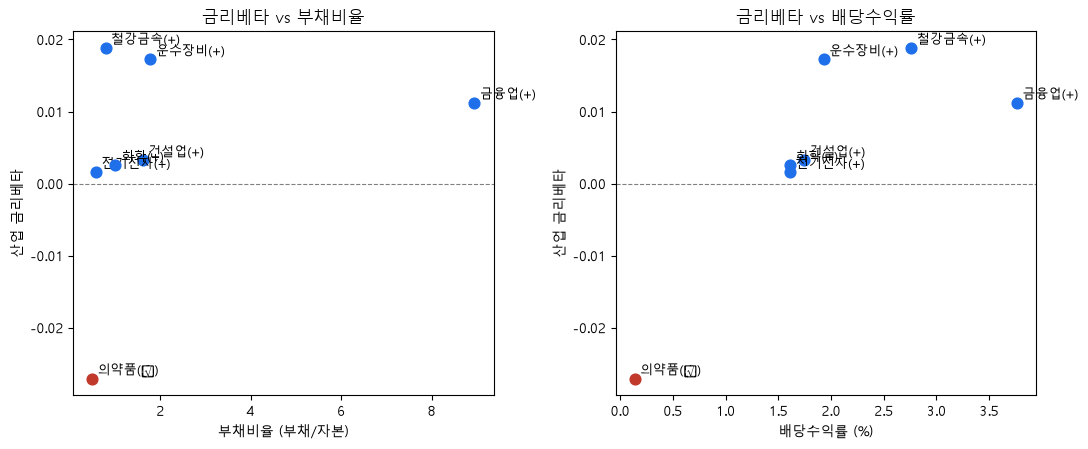

In [4]:
# [셀 4] 산점도 — 금리베타 vs 부채비율/배당수익률 (부호 색상: 음 빨강 / 양 파랑)
plots = [("부채비율_시총가중", "부채비율 (부채/자본)"), ("배당수익률_시총가중", "배당수익률 (%)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (col, xlab) in zip(axes, plots):
    d = pd.concat([beta.rename("beta"), char[col].rename("x")], axis=1).dropna()
    for ind, r in d.iterrows():
        color = config.SIGN_COLORS["neg"] if r["beta"] < 0 else config.SIGN_COLORS["pos"]
        ax.scatter(r["x"], r["beta"], s=60, color=color, zorder=3)
        sign = "−" if r["beta"] < 0 else "+"
        ax.annotate(f"{ind}({sign})", (r["x"], r["beta"]), fontsize=9, xytext=(4, 3), textcoords="offset points")
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    ax.set_xlabel(xlab); ax.set_ylabel("산업 금리베타")
    ax.set_title(f"금리베타 vs {xlab.split(' (')[0]}")
fig.tight_layout()
fig.savefig(H3_FIGDIR / "beta_vs_characteristics.png", dpi=130, bbox_inches="tight")
plt.show()


### 관찰 결과

- 가로축은 산업 재무특성, 세로축은 금리베타이며 각 점은 하나의 산업이다(빨강=음, 파랑=양). 기간은 2016~2025.
- 의약품이 배당수익률 최저·금리베타 음으로 좌하단에 위치하는지 확인한다.
- 시총가중과 중앙값 결과가 다른 경우 극단값·소수 대형주 영향을 고려한다.


## 의약품 R&D 보조근거

### 목적

- 의약품 기업의 매출 대비 R&D 비율을 제시해 낮은 배당수익률과 함께 '먼 미래 현금흐름 집중(긴 듀레이션)' 해석을 보강한다.
- 7개 산업 순위상관 변수가 아니라 의약품 해석의 보조 정황이며, R&D는 주식 듀레이션의 직접 측정이 아니다.


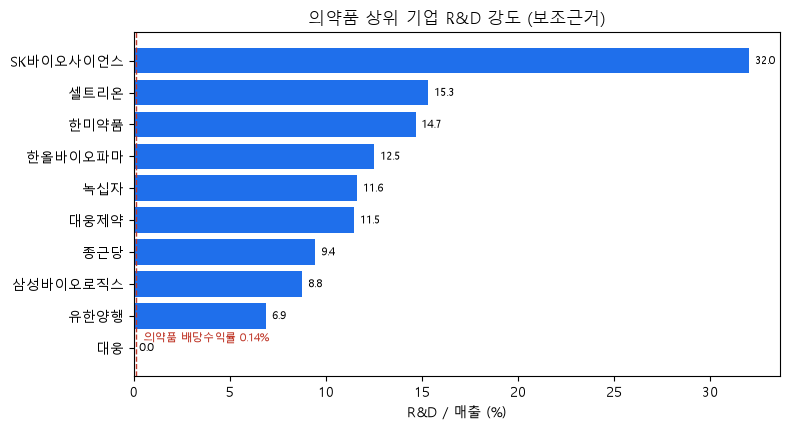

[의약품 대표 R&D/매출] 중앙값 11.6% · 배당수익률 0.14%(7산업 최저)
company_name  rnd_to_sales_pct                     기준
          대웅              0.01 DART 경상연구개발비/매출(비용처리분)
        유한양행              6.88 DART 경상연구개발비/매출(비용처리분)
    삼성바이오로직스              8.77  사업보고서 연구개발비/매출(연결·총계)
         종근당              9.45 DART 경상연구개발비/매출(비용처리분)
        대웅제약             11.48 DART 경상연구개발비/매출(비용처리분)
         녹십자             11.63  사업보고서 연구개발비/매출(연결·총계)
     한올바이오파마             12.53 DART 경상연구개발비/매출(비용처리분)
        한미약품             14.67 DART 경상연구개발비/매출(비용처리분)
        셀트리온             15.34  사업보고서 연구개발비/매출(연결·총계)
   SK바이오사이언스             32.03  사업보고서 연구개발비/매출(연결·총계)


In [5]:
# [셀 5] 의약품 R&D/매출 보조근거 표·그림 (한국어)
SUP = PROCESSED_DIR / "pharma_rnd_support.csv"
if SUP.exists():
    sup = pd.read_csv(SUP).dropna(subset=["rnd_to_sales_pct"]).sort_values("rnd_to_sales_pct")
    sup_core = sup[sup["company_name"] != "대웅"]  # 지주 제외
    div_pharma = float(char.loc["의약품", "배당수익률_시총가중"])
    fig, ax = plt.subplots(figsize=(8, 4.4))
    ax.barh(sup["company_name"], sup["rnd_to_sales_pct"], color=config.SIGN_COLORS["pos"])
    ax.axvline(div_pharma, color=config.SIGN_COLORS["neg"], ls="--", lw=1)
    ax.text(div_pharma + 0.4, 0.2, f"의약품 배당수익률 {div_pharma:.2f}%", color=config.SIGN_COLORS["neg"], fontsize=8)
    for y, v in enumerate(sup["rnd_to_sales_pct"]):
        ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8)
    ax.set_xlabel("R&D / 매출 (%)"); ax.set_title("의약품 상위 기업 R&D 강도 (보조근거)")
    fig.tight_layout(); fig.savefig(H3_FIGDIR / "pharma_rnd.png", dpi=130, bbox_inches="tight")
    plt.show()
    print(f"[의약품 대표 R&D/매출] 중앙값 {sup_core['rnd_to_sales_pct'].median():.1f}% · "
          f"배당수익률 {div_pharma:.2f}%(7산업 최저)")
    print(sup[["company_name", "rnd_to_sales_pct", "기준"]].round(2).to_string(index=False))
else:
    print("[SKIP] pharma_rnd_support.csv 없음 — STEP9 R&D 결합 셀 실행 필요")


### 관찰 결과

- 이 그림은 의약품 상위 기업의 매출 대비 R&D 비율을 보여주며, 빨간 파선은 의약품 배당수익률(7산업 최저)이다.
- 의약품이 낮은 배당과 높은 R&D를 동시에 보이는지 확인한다(전기전자 등도 R&D가 높아 산업 순위변수로는 쓰지 않음).


## 해석

- 배당수익률이 유의한 양의 순위상관(시총가중)을 보이면, 배당이 낮은 산업일수록 금리베타가 낮은(음) 방향으로, 의약품의 음의 금리베타와 정합적이다.
- 다만 시총가중과 중앙값에서 유의성이 갈리면 소수 대형기업 영향으로 해석하고 확증적으로 단정하지 않는다.
- 부채비율은 방향이 양이라도 비유의하면 '조달구조(레버리지) 차이로 설명되지 않는다'는 근거로 처리한다.
- 의약품 R&D는 낮은 배당과 함께 긴 듀레이션 해석을 보강하는 보조근거일 뿐 직접 원인 주장에 쓰지 않는다.
- 최신 구성종목 고정과 금융업 부채비율(예금=부채) 한계를 표본 한계로 명시한다.


## STEP10 요약

### Takeaway

- 7개 산업의 금리베타와 부채비율·배당수익률 간 순위 정렬을 탐색한다.
- 배당수익률은 시총가중에서 유의한 양의 순위상관을 보이나 중앙값에서는 약해져 집계방식에 민감하다.
- 부채비율은 방향이 양이나 비유의하며, 금융 포함·제외 두 벌을 병기한다.
- 의약품은 배당수익률 최저이면서 R&D/매출이 높아 긴 듀레이션 해석과 정합적이다(보조근거).
- 상세 내용: `results/H3_firm_characteristics/summary.md`
